# Forecasting PM2.5 in Nairobi Using Autoregressive (AR) Models and Model Order Selection

1. Memuat data

- import pandas, numpy, matplotlib.pyplot: library olah data, numerik, dan grafik.
- load_nairobi_to_mongodb(host=host): mengisi 10.000 dokumen ke MongoDB (localhost).
- wrangle_data(db=db, collection=collection, host=host).loc['2024']: mengambil data bersih lalu memilih tahun 2024.
- print(...) dan df.head(): 8.781 baris, 2024-01-01 sampai 2024-12-31 (zona waktu +03:00), kolom pm25.

In [7]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from load_mongo_data import load_nairobi_to_mongodb
from mongo_wrangle import wrangle_data


host = "localhost"

# Connect to MongoDB on localhost
load_nairobi_to_mongodb(host=host)

# Load data
db = "air-quality"
collection = "nairobi"
df = wrangle_data(db=db, collection=collection, host=host).loc['2024']

print(f"Data shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print("\nFirst 5 rows:")
df.head()

✅ Nairobi data successfully loaded to MongoDB at localhost:27017!
   Collection: air-quality.nairobi | Documents inserted: 10000
Data shape: (8781, 1)
Date range: 2024-01-01 03:00:00+03:00 to 2024-12-31 23:00:00+03:00

First 5 rows:


,pm25
timestamp,
2024-01-01 03:00:00+03:00,45.42
2024-01-01 04:00:00+03:00,28.71
2024-01-01 05:00:00+03:00,30.34
2024-01-01 06:00:00+03:00,28.35
2024-01-01 07:00:00+03:00,52.78


2. Fungsi ACF dan PACF manual

- _acf_manual(x, nlags): menghitung autokorelasi (korelasi nilai dengan nilai di lag sebelumnya) tanpa statsmodels. Data dikurangi rata-rata, lalu np.dot(x[:n-k], x[k:]) / denom.
- _pacf_manual(x, nlags): menghitung autokorelasi parsial lewat persamaan Yule-Walker. Matriks Toeplitz dibuat dari nilai ACF, diselesaikan dengan np.linalg.solve, dan koefisien terakhir diambil sebagai PACF di tiap lag.
- plot_acf_pacf(series, lags=20): menggambar ACF dan PACF berdampingan dengan pita kepercayaan 95% (ci = 1.96 / sqrt(n)), memakai vlines, scatter, axhspan, dan axhline.
- plot_acf_pacf(df['pm25'], lags=20): memanggil fungsi tersebut untuk data PM2.5.

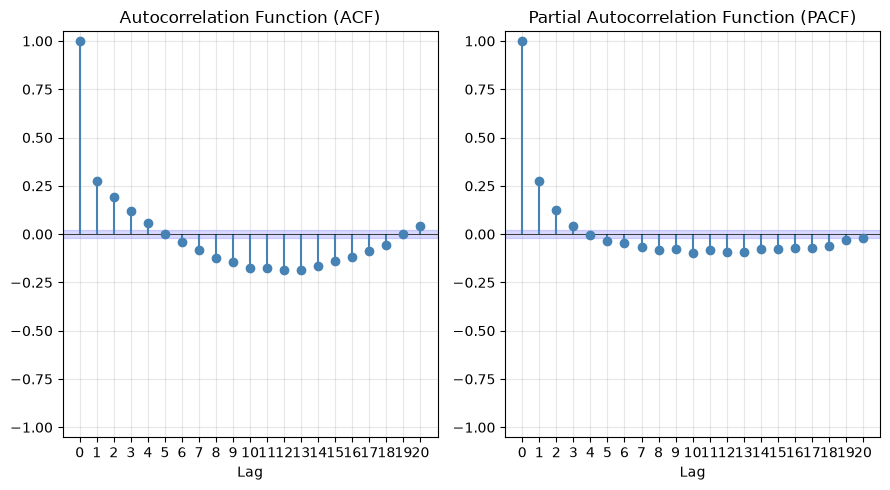

In [8]:
import numpy as np
import matplotlib.pyplot as plt


def _acf_manual(x, nlags):
    """
    Compute the autocorrelation function up to nlags.
    
    Returns array of length nlags+1, with acf[0] = 1.0 by definition.
    Uses the biased estimator (denominator = n for all lags), which is
    the convention statsmodels uses by default.
    """
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = len(x)
    denom = np.dot(x, x)  # variance * n, equivalent to sum of squared deviations
    return np.array([np.dot(x[:n - k], x[k:]) / denom for k in range(nlags + 1)])


def _pacf_manual(x, nlags):
    """
    Compute the partial autocorrelation function up to nlags via Yule-Walker.
    
    For each lag k, fits an AR(k) model and takes the last coefficient as
    the PACF value at lag k. PACF[0] is 1.0 by definition.
    """
    acf_vals = _acf_manual(x, nlags)
    pacf_vals = [1.0]
    for k in range(1, nlags + 1):
        # Toeplitz matrix R of size k x k built from acf values
        R = np.array([[acf_vals[abs(i - j)] for j in range(k)] for i in range(k)])
        r = acf_vals[1:k + 1]
        phi = np.linalg.solve(R, r)
        pacf_vals.append(phi[-1])
    return np.array(pacf_vals)


def plot_acf_pacf(series, lags=20):
    """
    Plot ACF and PACF for a time series — manual implementation, no statsmodels.
    
    Parameters
    ----------
    series : pd.Series or array-like
        Time series data
    lags : int
        Number of lags to plot
    """
    values = np.asarray(series)
    n = len(values)
    
    acf_vals = _acf_manual(values, lags)
    pacf_vals = _pacf_manual(values, lags)
    
    # 95% confidence band: ±1.96/sqrt(n) is the standard approximation
    # (Bartlett's formula simplified for the null hypothesis of white noise)
    ci = 1.96 / np.sqrt(n)
    
    fig, axes = plt.subplots(1, 2, figsize=(9, 5))
    x_lags = np.arange(lags + 1)
    
    for ax, vals, title in [(axes[0], acf_vals, 'Autocorrelation Function (ACF)'),
                            (axes[1], pacf_vals, 'Partial Autocorrelation Function (PACF)')]:
        ax.vlines(x_lags, 0, vals, colors='steelblue', linewidth=1.5)
        ax.scatter(x_lags, vals, color='steelblue', zorder=3)
        ax.axhspan(-ci, ci, alpha=0.15, color='blue')  # 95% confidence band
        ax.axhline(0, color='black', linewidth=0.5)
        ax.set_title(title)
        ax.set_xlabel('Lag')
        ax.set_xticks(x_lags)
        ax.grid(True, alpha=0.3)
        ax.set_ylim(-1.05, 1.05)
    
    plt.tight_layout()
    plt.show()


# Plot ACF and PACF for PM2.5 data
plot_acf_pacf(df['pm25'], lags=20)

3. Memilih orde AR

- ar_order = 5: orde AR ditetapkan 5.
- print(...): penjelasan bahwa PACF signifikan sampai lag 5. 

In [9]:
# Based on the PACF plot, determine the AR order
# Looking at typical air quality data, we'll use p=5 as an example
ar_order = 5

print(f"Chosen AR order: p = {ar_order}")
print(f"\nReasoning: The PACF plot shows significant spikes up to lag {ar_order},")
print(f"after which values drop into the confidence band (are not statistically significant).")
print(f"This suggests an AR({ar_order}) model is appropriate.")

Chosen AR order: p = 5

Reasoning: The PACF plot shows significant spikes up to lag 5,
after which values drop into the confidence band (are not statistically significant).
This suggests an AR(5) model is appropriate.


4. Split kronologis

- split_idx = int(len(df) * 0.8): titik pembagian 80%.
- .iloc[:split_idx] dan .iloc[split_idx:]: 7.024 data latih (sampai 2024-10-19 18:00) dan 1.757 data uji (setelahnya).

In [10]:
# Calculate split index (80% for training)
split_idx = int(len(df) * 0.8)

# Split chronologically
train_data = df['pm25'].iloc[:split_idx]
test_data = df['pm25'].iloc[split_idx:]

print(f"Training set: {len(train_data)} observations")
print(f"Testing set: {len(test_data)} observations")
print(f"\nTraining period: {train_data.index.min()} to {train_data.index.max()}")
print(f"Testing period: {test_data.index.min()} to {test_data.index.max()}")

Training set: 7024 observations
Testing set: 1757 observations

Training period: 2024-01-01 03:00:00+03:00 to 2024-10-19 18:00:00+03:00
Testing period: 2024-10-19 19:00:00+03:00 to 2024-12-31 23:00:00+03:00


5. Baseline persistence

- test_data.shift(1).dropna(): prediksi dengan nilai sebelumnya.
- test_data[1:]: nilai asli yang disejajarkan.
- mean_absolute_error(...): MAE baseline 9,26.

In [11]:
from sklearn.metrics import mean_absolute_error

# Persistence baseline: predict using last observed value
y_pred_baseline = test_data.shift(1).dropna()
y_true_baseline = test_data[1:]  # Align with shifted predictions

# Calculate baseline MAE
mae_baseline = mean_absolute_error(y_true_baseline, y_pred_baseline)

print(f"Baseline (Persistence) MAE: {mae_baseline:.2f}")

Baseline (Persistence) MAE: 9.26


6. Melatih model AR(5)

- AutoReg(train_data, lags=ar_order).fit(): melatih model autoregressive.
- model_ar_fitted.summary(): ringkasan statistik. Koefisien lag 1 sampai 3 signifikan (0,232, 0,117, 0,053), lag 4 tidak signifikan (p = 0,647), lag 5 negatif kecil (-0,034). Semua akar berada di luar lingkaran satuan (modulus > 1), jadi model stasioner.

In [12]:
from statsmodels.tsa.ar_model import AutoReg

# Fit AR model
model_ar = AutoReg(train_data, lags=ar_order)
model_ar_fitted = model_ar.fit()

# Print summary
print(model_ar_fitted.summary())

                            AutoReg Model Results                             
Dep. Variable:                   pm25   No. Observations:                 7019
Model:                     AutoReg(5)   Log Likelihood              -25642.950
Method:               Conditional MLE   S.D. of innovations              9.341
Date:                Wed, 21 Oct 2026   AIC                          51299.900
Time:                        10:51:34   BIC                          51347.894
Sample:                    01-01-2024   HQIC                         51316.435
                         - 10-19-2024                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         24.7611      0.763     32.437      0.000      23.265      26.257
pm25.L1        0.2324      0.012     19.487      0.000       0.209       0.256
pm25.L2        0.1170      0.012      9.559      0.0

c:\Users\jason\.conda\envs\ds-project\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


7. Mengambil koefisien

- model_ar_fitted.params: parameter model.
- if 'const' in params.index ... else ...: menangani perbedaan versi statsmodels.
- pd.DataFrame({'Lag': ..., 'Coefficient': ...}): tabel koefisien. Konstanta = 24,76.

In [13]:
# Extract coefficients
params = model_ar_fitted.params # <-- pass in `params` here

# Handle different AutoReg versions
if 'const' in params.index:
    constant = params['const']
    ar_coeffs = params.drop('const')
else:
    constant = params.iloc[0] if len(params) > ar_order else 0
    ar_coeffs = params[-ar_order:] if len(params) > ar_order else params

# Create DataFrame
coefficients_df = pd.DataFrame({
    'Lag': range(1, len(ar_coeffs) + 1),
    'Coefficient': ar_coeffs.values
})

print("AR Model Coefficients:")
print(coefficients_df)
print(f"\nConstant: {constant:.4f}")

AR Model Coefficients:
   Lag  Coefficient
0    1     0.232408
1    2     0.117029
2    3     0.052934
3    4     0.005613
4    5    -0.033842

Constant: 24.7611


8. Walk-forward validation

- warnings.filterwarnings(...): menyembunyikan peringatan statsmodels.
- max_predictions = 30: hanya 30 prediksi pertama (demi kecepatan).
- Loop for t in range(...): tiap langkah melatih ulang AutoReg pada riwayat saat ini, memprediksi 1 langkah (forecast(steps=1)), lalu menambahkan nilai aktual ke history dengan pd.concat.
- pd.Series(predictions, index=test_data.index[:len(predictions)]): hasil prediksi ber-indeks waktu. Contoh 5 prediksi pertama sekitar 41 sampai 44.

In [14]:
import pandas as pd
from statsmodels.tsa.ar_model import AutoReg
import warnings

# Menghilangkan warning dari statsmodels
warnings.filterwarnings("ignore", category=Warning, module="statsmodels")

max_predictions = 30

# Initialize predictions list
predictions = []
history = train_data.copy().reset_index(drop=True)

# Walk-forward validation
for t in range(min(max_predictions, len(test_data))):
    # Fit model on current history
    model = AutoReg(history, lags=ar_order)
    model_fitted = model.fit()

    # Make one-step-ahead prediction
    y_pred = model_fitted.forecast(steps=1)
    predictions.append(y_pred.iloc[0])

    # Add actual observation to history
    history = pd.concat(
        [history, test_data.iloc[[t]].reset_index(drop=True)],
        ignore_index=True
    )

# Convert predictions to Series
y_pred_ar = pd.Series(
    predictions,
    index=test_data.index[:len(predictions)]
)

print(f"Generated {len(y_pred_ar)} walk-forward predictions")
print("\nFirst 5 predictions:")
print(y_pred_ar.head())

Generated 30 walk-forward predictions

First 5 predictions:
timestamp
2024-10-19 19:00:00+03:00    41.059201
2024-10-19 20:00:00+03:00    41.262795
2024-10-19 21:00:00+03:00    40.654454
2024-10-19 22:00:00+03:00    43.965108
2024-10-19 23:00:00+03:00    44.236928
dtype: float64


9. Evaluasi AR(5)

- mean_absolute_error, np.sqrt(mean_squared_error(...)), r2_score pada 30 data uji.
- Hasil: MAE 7,82, RMSE 9,47, R² -0,004.
- Perbaikan terhadap baseline: 15,5%.

In [15]:
from sklearn.metrics import mean_squared_error, r2_score

# Align test data with predictions
y_true_ar = test_data.iloc[:len(y_pred_ar)]

# Calculate metrics
mae_ar = mean_absolute_error(y_true_ar, y_pred_ar)
rmse_ar = np.sqrt(mean_squared_error(y_true_ar, y_pred_ar))
r2_ar = r2_score(y_true_ar, y_pred_ar)

# Create comparison DataFrame (note: R² included for reference only)
comparison_df = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R²'],
    'AR Model': [mae_ar, rmse_ar, r2_ar],
    'Baseline': [mae_baseline, np.nan, np.nan]
})

print("Model Performance Comparison:")
print(comparison_df.round(4))
print("\n⚠️  Note: Focus on MAE/RMSE for time series, not R²")

print(f"\n📊 Improvement over baseline:")
print(f"   Baseline MAE: {mae_baseline:.2f}")
print(f"   AR Model MAE: {mae_ar:.2f}")
if mae_ar < mae_baseline:
    improvement = ((mae_baseline - mae_ar) / mae_baseline) * 100
    print(f"   ✅ {improvement:.1f}% better than baseline")
else:
    print(f"   ⚠️ Model did not beat baseline")

Model Performance Comparison:
  Metric  AR Model  Baseline
0    MAE    7.8219    9.2595
1   RMSE    9.4664       NaN
2     R²   -0.0037       NaN

⚠️  Note: Focus on MAE/RMSE for time series, not R²

📊 Improvement over baseline:
   Baseline MAE: 9.26
   AR Model MAE: 7.82
   ✅ 15.5% better than baseline


10. Grafik hasil

- Panel 1: garis aktual dan prediksi AR di 30 titik uji (prediksi tampak “halus” karena mean reversion).
- Panel 2: diagram batang koefisien AR dengan garis nol merah.

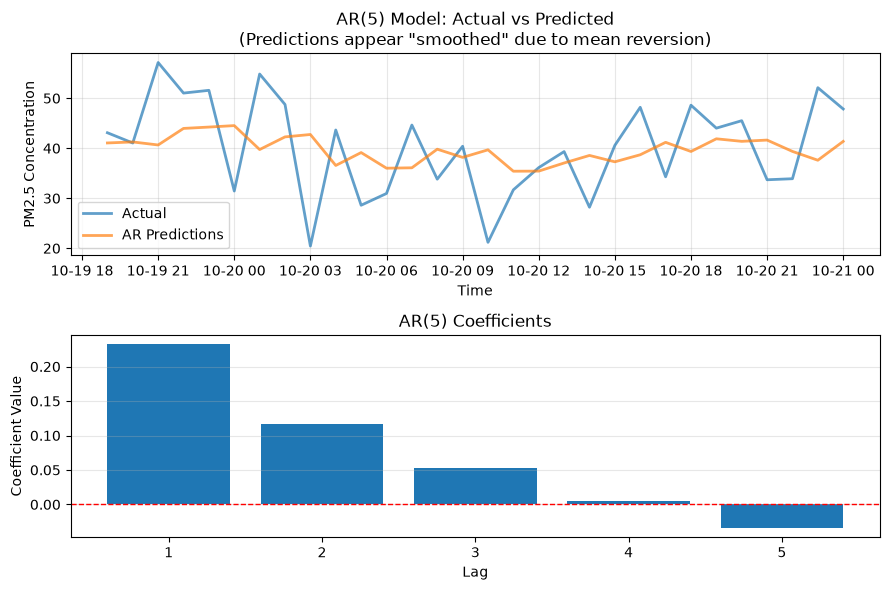

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6))

# Plot 1: Actual vs Predicted
axes[0].plot(y_true_ar.index, y_true_ar, label='Actual', alpha=0.7, linewidth=2)
axes[0].plot(y_pred_ar.index, y_pred_ar, label='AR Predictions', alpha=0.7, linewidth=2)
axes[0].set_xlabel('Time')
axes[0].set_ylabel('PM2.5 Concentration')
axes[0].set_title(f'AR({ar_order}) Model: Actual vs Predicted\n(Predictions appear "smoothed" due to mean reversion)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: AR Coefficients
axes[1].bar(coefficients_df['Lag'], coefficients_df['Coefficient'])
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('Coefficient Value')
axes[1].set_title(f'AR({ar_order}) Coefficients')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.show()

11. Fungsi evaluate_ar_order dan Membandingkan orde AR

- Menjalankan walk-forward untuk satu orde AR: AutoReg(history, lags=order, trend="c"), forecast(steps=1), dan history.loc[len(history)] = test_values[t].
- Index diubah ke numerik agar tidak memicu peringatan waktu.
- Mengembalikan MAE (walk-forward) serta AIC dan BIC dari model yang dilatih pada seluruh data latih.
- Loop orders = [1, 3, 5, 7], hasil dikumpulkan di results_dict, lalu pd.DataFrame(results_dict).T.
- idxmin(): AR(7) terbaik pada ketiga ukuran (MAE, AIC, BIC).

In [17]:

import warnings
import pandas as pd
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_absolute_error

# Menghilangkan warning spesifik dari statsmodels
warnings.filterwarnings(
    "ignore",
    message="No frequency information was provided.*",
    category=Warning,
)

warnings.filterwarnings(
    "ignore",
    message="Only PeriodIndexes, DatetimeIndexes.*",
    category=UserWarning,
)

def evaluate_ar_order(order, train_data, test_data, max_pred=30):
    """
    Evaluasi model AR menggunakan walk-forward validation,
    MAE, AIC, dan BIC.
    """
    predictions = []
    history = train_data.copy()

    # Gunakan index numerik agar forecast tidak memicu warning index waktu
    history.index = range(len(history))
    test_values = test_data.to_numpy()

    for t in range(min(max_pred, len(test_values))):
        model = AutoReg(history, lags=order, trend="c")
        model_fitted = model.fit()

        # Prediksi satu langkah ke depan
        y_pred = model_fitted.forecast(steps=1)
        predictions.append(float(y_pred.iloc[0]))

        # Tambahkan nilai aktual ke history
        history.loc[len(history)] = test_values[t]

    # Hitung MAE
    y_true = test_values[:len(predictions)]
    mae = mean_absolute_error(y_true, predictions)

    # Hitung AIC dan BIC dari data training
    train_numeric = train_data.reset_index(drop=True)
    full_model = AutoReg(
        train_numeric,
        lags=order,
        trend="c"
    ).fit()

    return mae, full_model.aic, full_model.bic


# Uji beberapa orde AR
orders = [1, 3, 5, 7]
results_dict = {}

for order in orders:
    print(f"Testing AR({order})...")

    mae, aic, bic = evaluate_ar_order(
        order,
        train_data,
        test_data,
        max_pred=30
    )

    results_dict[order] = {
        "MAE": mae,
        "AIC": aic,
        "BIC": bic
    }

    print(f"  MAE: {mae:.2f} | AIC: {aic:.1f} | BIC: {bic:.1f}")


# Tabel perbandingan
comparison_table = pd.DataFrame(results_dict).T
comparison_table.index.name = "AR Order"

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print(comparison_table.round(2))
print("=" * 60)

# Model dengan AIC dan BIC terkecil
print("\nModel dengan AIC terkecil:", comparison_table["AIC"].idxmin())
print("Model dengan BIC terkecil:", comparison_table["BIC"].idxmin())
print("Model dengan MAE terkecil:", comparison_table["MAE"].idxmin())


Testing AR(1)...
  MAE: 7.92 | AIC: 51461.5 | BIC: 51482.0
Testing AR(3)...
  MAE: 7.78 | AIC: 51320.8 | BIC: 51355.1
Testing AR(5)...
  MAE: 7.82 | AIC: 51299.9 | BIC: 51347.9
Testing AR(7)...
  MAE: 7.76 | AIC: 51238.5 | BIC: 51300.2

MODEL COMPARISON
           MAE       AIC       BIC
AR Order                          
1         7.92  51461.48  51482.05
3         7.78  51320.82  51355.10
5         7.82  51299.90  51347.89
7         7.76  51238.45  51300.16

Model dengan AIC terkecil: 7
Model dengan BIC terkecil: 7
Model dengan MAE terkecil: 7


📊 Membaca Tabel Perbandingan Orde:
- AIC Terendah — model yang paling seimbang antara kualitas kecocokan dan jumlah parameter (dengan penalti kompleksitas moderat). Pilih ini ketika performa prediksi menjadi tujuannya.
- BIC Terendah — penalti yang lebih ketat terhadap kompleksitas daripada AIC. Pilih ini ketika parsimoni menjadi tujuannya (BIC cenderung lebih menyukai $p$ yang lebih kecil).
- MAE Terendah (walk-forward) — model yang secara empiris terbaik pada jendela 30 prediksi. Sikapi dengan hati-hati: jendela 30 sampel adalah kecil, dan perbedaan peringkat di bawah ~5% harus diperlakukan sebagai hasil yang imbang.
- Keputusan: Ketika AIC/BIC dan MAE sejalan, pilihannya menjadi jelas. Ketika keduanya tidak sejalan, percayai AIC/BIC pada jendela kecil dan MAE walk-forward pada jendela besar (ratusan prediksi).

⚠️ Kesalahan umum 
- Mengejar perbedaan MAE 0.06 seolah-olah itu bermakna. 
- Validasi walk-forward dalam pelajaran ini hanya menggunakan ~30 prediksi dari set pengujian sekitar ~1.750. 
- Perbedaan MAE sebesar 0.06 antara AR(5) dan AR(7) pada jendela 30 sampel adalah noise, bukan sinyal. 
- Langkah yang tepat ketika perbedaan MAE sekecil ini tidak sejalan dengan PACF atau AIC/BIC adalah mempercayai kriteria statistik, bukan angka empirisnya. 
- Kesalahan ini terasa menggoda karena MAE yang lebih rendah terasa seperti bukti — tetapi bukti memerlukan ukuran sampel, dan 30 belumlah cukup. 
- Sebagai aturan praktis: ketika perbedaan MAE antar model kandidat lebih kecil dari ~10% dari MAE baseline, perlakukan mereka sebagai hasil yang imbang dan putuskan keimbangannya menggunakan kesederhanaan model (AIC/BIC), bukan peringkat empiris.

Kesimpulan singkat

- Notebook ini memodelkan PM2.5 Nairobi tahun 2024 dengan model autoregressive. 
- Fungsi ACF dan PACF ditulis manual untuk melihat pola ketergantungan antar waktu. 
- Model AR(5) dilatih pada 80% data pertama dan dievaluasi dengan walk-forward validation. 
- MAE-nya 7,82, sekitar 15,5% lebih baik dari baseline persistence (9,26). 
- Perbandingan beberapa orde menunjukkan AR(7) sedikit lebih unggul (MAE 7,76, AIC dan BIC terendah), tetapi selisihnya kecil dibanding AR(3) atau AR(5). 
- Nilai R² mendekati nol, jadi model hanya menangkap sebagian kecil pola, dan prediksinya cenderung mengarah ke rata-rata. 
- Pola harian (musiman) atau variabel lain sebaiknya dipertimbangkan untuk hasil yang lebih baik.

Catatan: evaluasi hanya memakai 30 data uji (dari 1.757), jadi perbedaan MAE antar orde (sekitar 0,1) terlalu kecil untuk disimpulkan kuat. Pemilihan p = 5 tampaknya contoh, bukan hasil pembacaan PACF, dan AIC/BIC justru menunjuk orde 7. 